# Gradient Descent for Linear Regression

Objectieve: Implement gradient descent for linear regression and visualize the cost function.

# Gradient descent
Gradient descent is an iterative mathematical optimization algorithm used to minimize a model's error (called a cost or loss function) by continuously adjusting its internal parameters.

Initialize -> Predict -> Calculate Cost -> Calculate Gradient -> Update Parameters -> Repeat


# 3D Cost Surface
Visualize the cost surface using contour and 3D surface plots.
Because we have two parameters:

 θ0,θ1
	​

we can visualize how the cost changes as these parameters change.\
Imagine:

X-axis → θ0\
Y-axis → θ1
	​

Z-axis → J(θ0,θ1)\
It'll reseamble something like a bowl.

# Contour Plot
A contour plot is basically the top view of that 3D bowl.

# Experiment 3: Gradient Descent for Linear Regression

## Objective

The objective of this experiment is to implement linear regression using
gradient descent and visualize the cost function.

### Tasks
1. Implement the cost function for linear regression.
2. Implement gradient descent to minimize the cost.
3. Visualize the decrease in cost during gradient descent.
4. Visualize the cost function using contour and 3D surface plots.
5. Compare the gradient descent solution with the closed-form solution
   (Normal Equation).

Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Create the Dataset

- **Feature (X):** Study Hours
- **Target (Y):** Exam Score

The purpose is to learn a linear relationship between study hours and
exam score.

The linear regression hypothesis is:

\[
y^​=θ0​+θ1​x
\]

where:

- \(x\) represents study hours.
- y^ represents the predicted exam score.
- θ0 = represents the intercept.
- θ1 = represents the slope.

In [2]:
# Create the dataset
data = {
    'Study_Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Exam_Score': [35, 40, 50, 55, 65, 70, 75, 85, 90, 95]
}

df = pd.DataFrame(data)

# Display the dataset
df

,Study_Hours,Exam_Score
0,1,35
1,2,40
2,3,50
3,4,55
4,5,65
5,6,70
6,7,75
7,8,85
8,9,90
9,10,95


Extracting the values of Features and Target

In [3]:
# Extract input and output
X = df['Study_Hours'].values
y = df['Exam_Score'].values

# Number of training examples
m = len(X)

print("X =", X)
print("y =", y)
print("Number of training examples (m) =", m)

X = [ 1  2  3  4  5  6  7  8  9 10]
y = [35 40 50 55 65 70 75 85 90 95]
Number of training examples (m) = 10


Visualize the Dataset

The scatter plot shows the relationship between study hours and exam
score.

If the points approximately follow a straight-line pattern, linear
regression can be used to model the relationship.

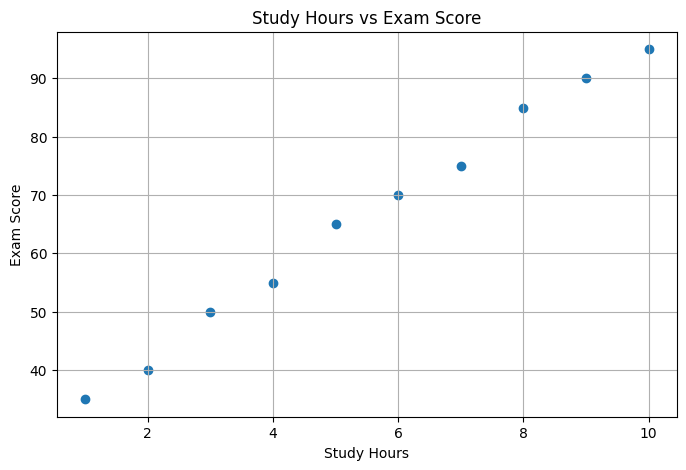

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.grid(True)
plt.show()

Defining the Linear Regression Hypothesis

Initially, the values of 00 and 01 are unknown.\
Gradient descent will iteratively update these parameters to find the values that minimize the cost function.

In [5]:
# Initial parameter values
theta_0 = 0
theta_1 = 0

# Calculate predictions
y_pred = theta_0 + theta_1 * X

print("Initial theta_0:", theta_0)
print("Initial theta_1:", theta_1)
print("Initial predictions:", y_pred)

Initial theta_0: 0
Initial theta_1: 0
Initial predictions: [0 0 0 0 0 0 0 0 0 0]


Implementing the Cost Function

The cost function calculates the initial error of the linear regression model.\
A high cost indicates that the predictions are far from the actual values.\
As gradient descent updates θ0 and θ1, the cost should progressively decrease, indicating improved model performance.

In [6]:
def compute_cost(X, y, theta_0, theta_1):
    """
    Compute the cost function for linear regression.
    """
    
    m = len(y)
    
    # Predictions
    predictions = theta_0 + theta_1 * X
    
    # Calculate squared errors
    errors = predictions - y
    
    # Cost
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    
    return cost

Initial Cost

In [7]:
initial_cost = compute_cost(X, y, theta_0, theta_1)

print("Initial Cost =", initial_cost)

Initial Cost = 2372.5


Calculate the Gradient\
Gradient descent moves in the **opposite direction of the gradient**\
because we want to minimize the cost.

In [8]:
def compute_gradients(X, y, theta_0, theta_1):
    """
    Compute gradients for theta_0 and theta_1.
    """
    
    m = len(y)
    
    # Predictions
    predictions = theta_0 + theta_1 * X
    
    # Error
    errors = predictions - y
    
    # Gradients
    d_theta_0 = (1 / m) * np.sum(errors)
    d_theta_1 = (1 / m) * np.sum(errors * X)
    
    return d_theta_0, d_theta_1

Initial Gradient

In [9]:
d_theta_0, d_theta_1 = compute_gradients(
    X, y, theta_0, theta_1
)

print("Gradient for theta_0 =", d_theta_0)
print("Gradient for theta_1 =", d_theta_1)

Gradient for theta_0 = -66.0
Gradient for theta_1 = -419.5


Implement Gradient Descent

Gradient descent successfully optimizes the model parameters by repeatedly reducing the cost function.\
 As the number of iterations increases, the cost approaches its minimum value, indicating that the model's predictions are becoming closer to the actual values.

In [10]:
def gradient_descent(X, y, theta_0, theta_1, learning_rate, iterations):
    """
    Perform gradient descent for linear regression.
    """
    
    cost_history = []
    
    for i in range(iterations):
        
        # Compute gradients
        d_theta_0, d_theta_1 = compute_gradients(
            X, y, theta_0, theta_1
        )
        
        # Update parameters
        theta_0 = theta_0 - learning_rate * d_theta_0
        theta_1 = theta_1 - learning_rate * d_theta_1
        
        # Calculate and store cost
        cost = compute_cost(X, y, theta_0, theta_1)
        cost_history.append(cost)
    
    return theta_0, theta_1, cost_history

Run Gradient Descent

After 1000 iterations, gradient descent updates θ0 and θ1 to values that minimize the cost function. The final values of these parameters are used to construct the trained linear regression model:\
y^=θ0+θ1x

The decrease in cost indicates that the model has learned a better relationship between the input feature X and target variable y.

In [11]:
# Initial parameters
theta_0 = 0
theta_1 = 0

# Hyperparameters
learning_rate = 0.01
iterations = 1000

# Run gradient descent
theta_0, theta_1, cost_history = gradient_descent(
    X,
    y,
    theta_0,
    theta_1,
    learning_rate,
    iterations
)

print("Final theta_0 =", theta_0)
print("Final theta_1 =", theta_1)
print("Final Cost =", cost_history[-1])

Final theta_0 = 25.05838387406564
Final theta_1 = 7.3189003928164755
Final Cost = 2.1795683804268235


Plot Cost vs Iterations

The cost should decrease as gradient descent progresses.

The graph below shows how the cost function changes with each
iteration.

A decreasing curve indicates that gradient descent is successfully
minimizing the cost function.

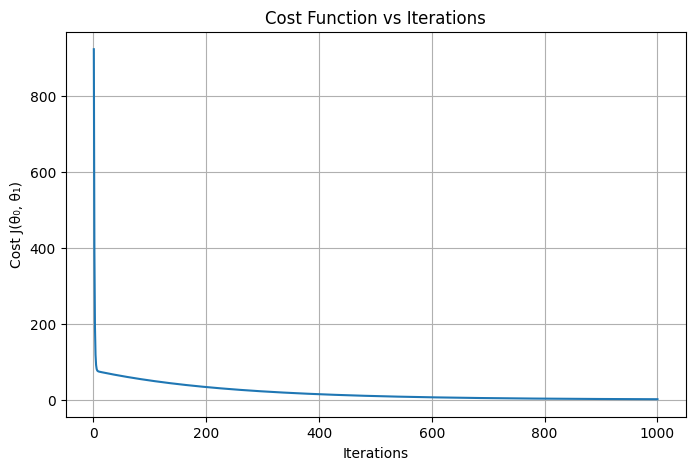

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, iterations + 1), cost_history)

plt.xlabel("Iterations")
plt.ylabel("Cost J(θ₀, θ₁)")
plt.title("Cost Function vs Iterations")

plt.grid(True)
plt.show()

Plot the Final Regression Line

After gradient descent converges, the learned parameters are used to
calculate the predicted exam scores.

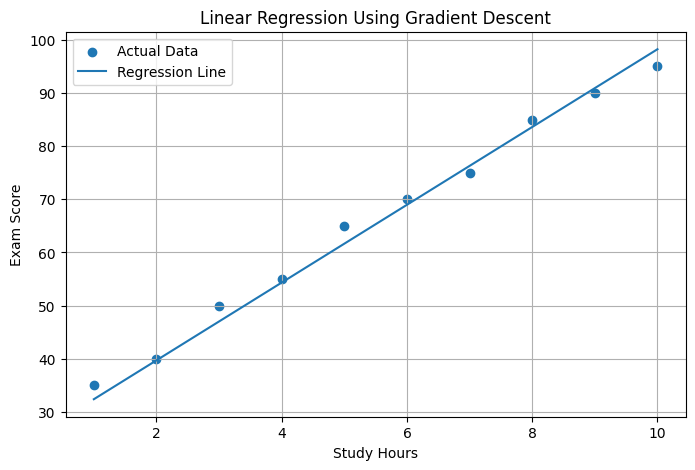

In [13]:
# Predictions using optimized parameters
y_pred = theta_0 + theta_1 * X

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Data")
plt.plot(X, y_pred, label="Regression Line")

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Linear Regression Using Gradient Descent")

plt.legend()
plt.grid(True)
plt.show()

Creating a Grid of θ₀ and θ₁ Values (cost surface)

In [15]:
# Create ranges of theta values
theta_0_values = np.linspace(-10, 50, 100)
theta_1_values = np.linspace(0, 15, 100)

# Create a mesh grid
theta_0_grid, theta_1_grid = np.meshgrid(
    theta_0_values,
    theta_1_values
)

# Initialize cost matrix
cost_grid = np.zeros(theta_0_grid.shape)

# Calculate cost for every combination
for i in range(theta_0_grid.shape[0]):
    for j in range(theta_0_grid.shape[1]):
        
        cost_grid[i, j] = compute_cost(
            X,
            y,
            theta_0_grid[i, j],
            theta_1_grid[i, j]
        )

print("Cost surface generated successfully.")

Cost surface generated successfully.


Contour Plot

The contour plot can be used to visualize how the cost function changes for different values of θ0 and θ1.\
Interpretation\
X-axis: θ0 — intercept parameter\
Y-axis: θ1 — slope parameter
Contour lines: Different values of the cost function J(θ0,θ1)\
Center of the contours: Approximate minimum cost\
Gradient descent: Moves the parameters from their initial values toward the center/minimum.

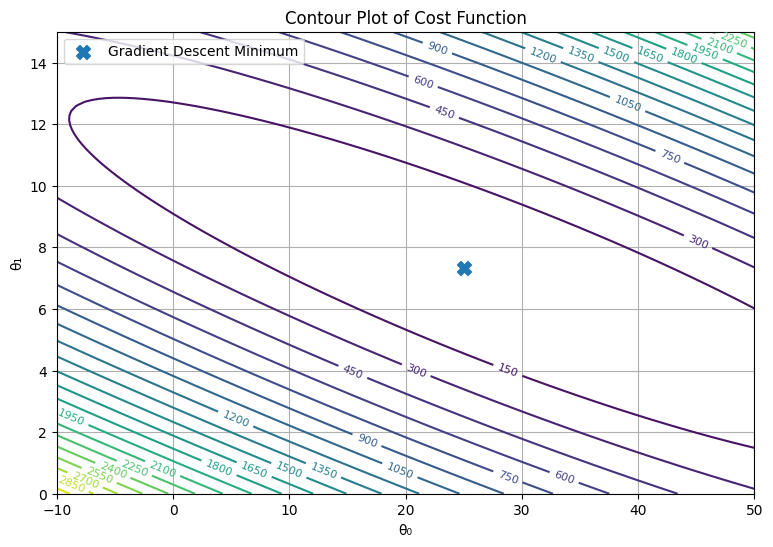

In [16]:
plt.figure(figsize=(9, 6))

# Contour plot
contours = plt.contour(
    theta_0_grid,
    theta_1_grid,
    cost_grid,
    levels=20
)

plt.clabel(contours, inline=True, fontsize=8)

# Gradient descent final point
plt.scatter(
    theta_0,
    theta_1,
    s=100,
    marker='X',
    label='Gradient Descent Minimum'
)

plt.xlabel("θ₀")
plt.ylabel("θ₁")
plt.title("Contour Plot of Cost Function")

plt.legend()
plt.grid(True)
plt.show()

Showing the Gradient Descent Path

The gradient descent path demonstrates how the parameters θ0 and θ1 are iteratively updated. Starting from (0,0), the algorithm moves toward the region of minimum cost. As the iterations increase, the movement becomes smaller and the parameters converge toward their optimal values.

In [ ]:
def gradient_descent_with_history(
    X, y, theta_0, theta_1, learning_rate, iterations
):
    """
    Perform gradient descent while storing:
    - theta_0 history
    - theta_1 history
    - cost history
    """
    
    theta_0_history = []
    theta_1_history = []
    cost_history = []
    
    for i in range(iterations):
        
        # Store current parameters
        theta_0_history.append(theta_0)
        theta_1_history.append(theta_1)
        
        # Calculate gradients
        d_theta_0, d_theta_1 = compute_gradients(
            X, y, theta_0, theta_1
        )
        
        # Update parameters
        theta_0 = theta_0 - learning_rate * d_theta_0
        theta_1 = theta_1 - learning_rate * d_theta_1
        
        # Calculate cost
        cost = compute_cost(
            X, y, theta_0, theta_1
        )
        
        cost_history.append(cost)
    
    return (
        theta_0,
        theta_1,
        theta_0_history,
        theta_1_history,
        cost_history
    )

In [22]:
# Initial parameters
theta_0_initial = 0
theta_1_initial = 0

# Run gradient descent
(
    theta_0,
    theta_1,
    theta_0_history,
    theta_1_history,
    cost_history
) = gradient_descent_with_history(
    X,
    y,
    theta_0_initial,
    theta_1_initial,
    learning_rate,
    iterations
)

print("Final θ₀ =", theta_0)
print("Final θ₁ =", theta_1)
print("Final Cost =", cost_history[-1])

Final θ₀ = 25.05838387406564
Final θ₁ = 7.3189003928164755
Final Cost = 2.1795683804268235


Contour Plot with Gradient Descent Path

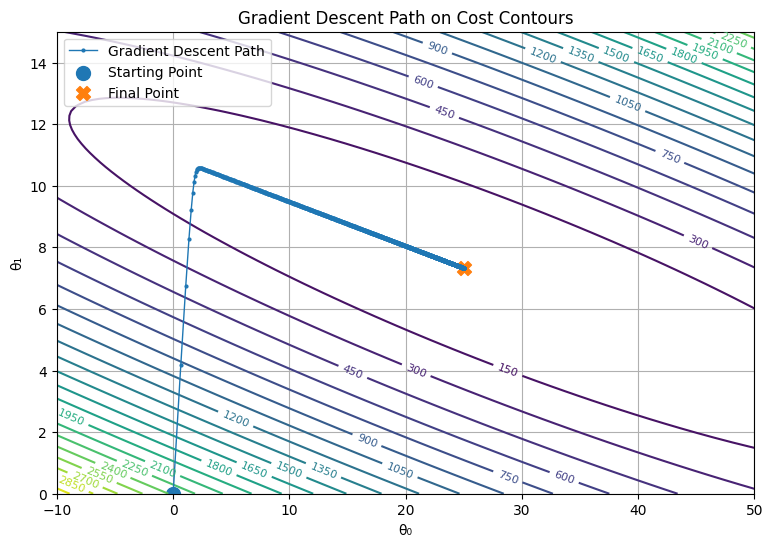

In [23]:
plt.figure(figsize=(9, 6))

# Cost contours
contours = plt.contour(
    theta_0_grid,
    theta_1_grid,
    cost_grid,
    levels=25
)

plt.clabel(contours, inline=True, fontsize=8)

# Gradient descent path
plt.plot(
    theta_0_history,
    theta_1_history,
    marker='o',
    markersize=2,
    linewidth=1,
    label='Gradient Descent Path'
)

# Starting point
plt.scatter(
    theta_0_history[0],
    theta_1_history[0],
    s=100,
    marker='o',
    label='Starting Point'
)

# Final point
plt.scatter(
    theta_0_history[-1],
    theta_1_history[-1],
    s=100,
    marker='X',
    label='Final Point'
)

plt.xlabel("θ₀")
plt.ylabel("θ₁")
plt.title("Gradient Descent Path on Cost Contours")

plt.legend()
plt.grid(True)
plt.show()

3D Cost Surface Plot

The 3D surface plot shows that the cost function has a bowl-shaped surface. The highest regions represent larger cost values, while the lowest point represents the minimum cost. The corresponding θ0 and θ1 values at this lowest point are the optimal parameters obtained through gradient descent.

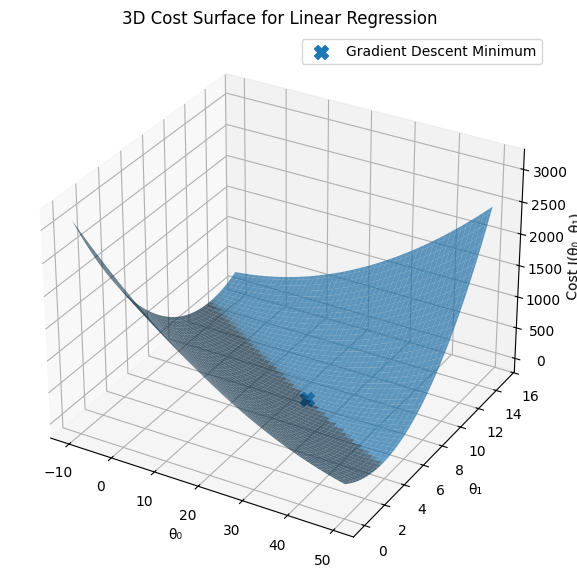

In [21]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection='3d')

# 3D surface
surface = ax.plot_surface(
    theta_0_grid,
    theta_1_grid,
    cost_grid,
    alpha=0.7
)

# Gradient descent final point
final_cost = compute_cost(
    X,
    y,
    theta_0,
    theta_1
)

ax.scatter(
    theta_0,
    theta_1,
    final_cost,
    s=100,
    marker='X',
    label='Gradient Descent Minimum'
)

ax.set_xlabel("θ₀")
ax.set_ylabel("θ₁")
ax.set_zlabel("Cost J(θ₀, θ₁)")

ax.set_title("3D Cost Surface for Linear Regression")

ax.legend()

plt.show()

## 18. Observation

1. Gradient descent successfully minimized the cost function for the
   linear regression model.

2. The cost decreased continuously with the number of iterations and
   eventually converged to a minimum value.

3. The contour plot showed the movement of the gradient descent
   algorithm from the initial parameter values toward the minimum-cost
   region.

4. The 3D surface plot represented the cost function as a bowl-shaped
   surface, where the lowest point corresponds to the optimal values
   of \(\theta_0\) and \(\theta_1\).

5. The parameters obtained using gradient descent were very close to
   those obtained using the closed-form Normal Equation.

6. The regression lines produced by both methods were almost
   identical, confirming that gradient descent successfully learned
   the linear relationship in the dataset.